# Notebook 3 — Expériences Texte & Deep Learning

**Objectif** : Benchmarker toutes les approches textuelles de l'équipe et générer des probabilités  
OOF (Out-Of-Fold) propres, sans data leakage, pour le stacking final.

**Modèles** :
1. **c-TF-IDF** : similarité cosinus par classe (27 features)
2. **multilingual-e5-large** : embeddings 1024-d mis en cache
3. **Fusion** : TF-IDF + c-TF-IDF + e5-large → LogReg ou MLP
4. **CamemBERT** (optionnel, cellule dédiée)

**Méthodologie OOF** : StratifiedKFold(5) sur le Train uniquement.  
Val et Test sont prédits sur le modèle entraîné sur le Train complet.

**Livrables** :
- `data/processed_clean/X_ctfidf_*.npy` — c-TF-IDF features
- `data/processed_clean/X_e5_*.npy` — embeddings e5-large
- `data/processed_clean/P_text_oof_train.npy` — probabilités OOF sur le train
- `data/processed_clean/P_text_val.npy` / `P_text_test.npy`
- `reports/figures/` — graphiques benchmark et interprétabilité

---

## 0. Configuration

In [7]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

from pathlib import Path

_NB_DIR = Path('__file__').resolve().parent if '__file__' in dir() else Path.cwd()
ROOT = _NB_DIR
for _ in range(5):
    if (ROOT / 'data' / 'raw').exists():
        break
    ROOT = ROOT.parent

CFG = {
    'root':        ROOT,
    'split_dir':   ROOT / 'data' / 'split_no_crop2',
    'processed':   ROOT / 'data' / 'processed_clean',
    'models_dir':  ROOT / 'models' / 'clean',
    'figures_dir': ROOT / 'reports' / 'figures',

    # OOF
    'n_folds':      5,
    'random_state': 42,
    'n_classes':    27,

    # Modele Sentence Transformers
    'e5_model_name': 'intfloat/multilingual-e5-large',
    'e5_batch_size': 64,
    'e5_prefix':     'query: ',  # prefixe requis par e5

    # LogReg
    'logreg_C':      1.0,
    'logreg_solver': 'saga',
    'logreg_max_iter': 1000,

    # MLP
    'mlp_hidden':    (256, 128, 64),
    'mlp_lr':        1e-3,
    'mlp_epochs':    50,
    'mlp_patience':  10,
    'mlp_batch':     256,
}

for d in ['processed', 'models_dir', 'figures_dir']:
    CFG[d].mkdir(parents=True, exist_ok=True)

print(f'ROOT : {ROOT}')

ROOT : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten


## 1. Imports

In [8]:
%matplotlib inline
import pickle
import logging
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s')
sns.set_theme(style='whitegrid')
print(f'Device : {device}')

def save_fig(name):
    plt.savefig(CFG['figures_dir'] / name, dpi=150, bbox_inches='tight')

Device : cuda


## 2. Chargement des données

In [9]:
train_df = pd.read_csv(CFG['split_dir'] / 'train.csv')
val_df   = pd.read_csv(CFG['split_dir'] / 'val.csv')
test_df  = pd.read_csv(CFG['split_dir'] / 'test.csv')

y_train = np.load(CFG['processed'] / 'y_train.npy')
y_val   = np.load(CFG['processed'] / 'y_val.npy')
y_test  = np.load(CFG['processed'] / 'y_test.npy')

# TF-IDF deja calcule dans le notebook 2
X_tfidf_train = sp.load_npz(CFG['processed'] / 'X_tfidf_train.npz')
X_tfidf_val   = sp.load_npz(CFG['processed'] / 'X_tfidf_val.npz')
X_tfidf_test  = sp.load_npz(CFG['processed'] / 'X_tfidf_test.npz')

with open(CFG['models_dir'] / 'tfidf_vectorizer.pkl', 'rb') as f:
    tfidf = pickle.load(f)

print(f'TF-IDF : {X_tfidf_train.shape}')
print(f'Train  : {len(train_df):,}  |  Val : {len(val_df):,}  |  Test : {len(test_df):,}')

TF-IDF : (59441, 50000)
Train  : 59,441  |  Val : 12,737  |  Test : 12,738


---
## 2.5 Traduction → text_fr (pour CamemBERT)

On traduit `combined_raw` en français uniquement pour les lignes non-françaises (~21% du dataset).
Les fichiers `*_fr.csv` sont mis en cache dans `split_dir` pour éviter de relancer la traduction.
On utilise `deep-translator` (GoogleTranslator), plus stable que la lib `googletrans`.

In [10]:
TRAIN_FR_PATH = CFG['split_dir'] / 'train_fr.csv'
VAL_FR_PATH   = CFG['split_dir'] / 'val_fr.csv'
TEST_FR_PATH  = CFG['split_dir'] / 'test_fr.csv'

if TRAIN_FR_PATH.exists() and VAL_FR_PATH.exists() and TEST_FR_PATH.exists():
    train_fr = pd.read_csv(TRAIN_FR_PATH)
    val_fr   = pd.read_csv(VAL_FR_PATH)
    test_fr  = pd.read_csv(TEST_FR_PATH)
    print(f'[CACHE] Fichiers *_fr.csv chargés.')
    print(f'  train_fr : {len(train_fr):,}  |  val_fr : {len(val_fr):,}  |  test_fr : {len(test_fr):,}')
else:
    try:
        from deep_translator import GoogleTranslator
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'deep-translator'])
        from deep_translator import GoogleTranslator

    def translate_df(df, text_col='combined_raw'):
        df = df.copy()
        mask = df['language'] != 'fr'
        texts_to_translate = df.loc[mask, text_col].fillna('').tolist()
        print(f'  Traduction de {mask.sum()} lignes non-françaises...')

        translated = []
        batch_size = 200
        for i in tqdm(range(0, len(texts_to_translate), batch_size)):
            batch = texts_to_translate[i:i+batch_size]
            try:
                batch_tr = [
                    GoogleTranslator(source='auto', target='fr').translate(t) or t
                    for t in batch
                ]
            except Exception as e:
                print(f'    Erreur batch {i//batch_size}: {e} — texte original conservé')
                batch_tr = batch
            translated.extend(batch_tr)

        df['text_fr'] = df[text_col].copy()
        df.loc[mask, 'text_fr'] = translated
        return df

    print('Traduction train...')
    train_fr = translate_df(train_df)
    print('Traduction val...')
    val_fr   = translate_df(val_df)
    print('Traduction test...')
    test_fr  = translate_df(test_df)

    train_fr.to_csv(TRAIN_FR_PATH, index=False)
    val_fr.to_csv(VAL_FR_PATH,     index=False)
    test_fr.to_csv(TEST_FR_PATH,   index=False)
    print('Fichiers *_fr.csv sauvegardés.')

print(f'\nExemple text_fr (non-fr) :')
sample = train_fr[train_fr['language'] != 'fr']['text_fr'].head(3)
for t in sample:
    print(f'  {str(t)[:100]}')

[CACHE] Fichiers *_fr.csv chargés.
  train_fr : 59,441  |  val_fr : 12,737  |  test_fr : 12,738

Exemple text_fr (non-fr) :
  Contes de Phantasia (version japonaise)
  Style Super One Piece : Punk Hazard (10 pièces) (Shokugan)
  Le message d'amour divin de Marie


---
## 3. Feature 1 : c-TF-IDF (Class TF-IDF)

Calcul des centroïdes TF-IDF par classe, puis similarité cosinus de chaque document  
avec chacun des 27 centroïdes. Cela produit 27 features interprétables par produit.

> Inspiré de la méthode BERTopic. Veyss l'a utilisé comme features discriminantes.

In [4]:
from sklearn.metrics.pairwise import cosine_similarity

def compute_ctfidf_centroids(X_tfidf: sp.csr_matrix, y: np.ndarray, n_classes: int) -> np.ndarray:
    """
    Calcule les centroïdes TF-IDF par classe (moyenne des vecteurs TF-IDF de chaque classe).

    Returns
    -------
    centroids : np.ndarray, shape (n_classes, n_features)
    """
    n_features = X_tfidf.shape[1]
    centroids = np.zeros((n_classes, n_features), dtype=np.float32)
    for cls in range(n_classes):
        mask = (y == cls)
        if mask.sum() > 0:
            centroids[cls] = np.asarray(X_tfidf[mask].mean(axis=0))
    return centroids


def apply_ctfidf(X_tfidf: sp.csr_matrix, centroids: np.ndarray) -> np.ndarray:
    """
    Projette chaque document sur les 27 centroïdes (similarité cosinus).

    Returns
    -------
    X_ctfidf : np.ndarray, shape (n_samples, n_classes)
    """
    sims = cosine_similarity(X_tfidf, centroids)
    return sims.astype(np.float32)

print('c-TF-IDF : calcul des centroides...')

c-TF-IDF : calcul des centroides...


In [5]:
CTFIDF_CACHE = CFG['processed'] / 'X_ctfidf_train.npy'

if CTFIDF_CACHE.exists():
    X_ctfidf_train = np.load(CFG['processed'] / 'X_ctfidf_train.npy')
    X_ctfidf_val   = np.load(CFG['processed'] / 'X_ctfidf_val.npy')
    X_ctfidf_test  = np.load(CFG['processed'] / 'X_ctfidf_test.npy')
    print(f'c-TF-IDF charge depuis cache : {X_ctfidf_train.shape}')
else:
    centroids = compute_ctfidf_centroids(X_tfidf_train, y_train, CFG['n_classes'])
    X_ctfidf_train = apply_ctfidf(X_tfidf_train, centroids)
    X_ctfidf_val   = apply_ctfidf(X_tfidf_val,   centroids)
    X_ctfidf_test  = apply_ctfidf(X_tfidf_test,  centroids)

    np.save(CFG['processed'] / 'X_ctfidf_train.npy', X_ctfidf_train)
    np.save(CFG['processed'] / 'X_ctfidf_val.npy',   X_ctfidf_val)
    np.save(CFG['processed'] / 'X_ctfidf_test.npy',  X_ctfidf_test)
    np.save(CFG['models_dir'] / 'ctfidf_centroids.npy', centroids)
    print(f'c-TF-IDF calcule : {X_ctfidf_train.shape}')

c-TF-IDF calcule : (59441, 27)


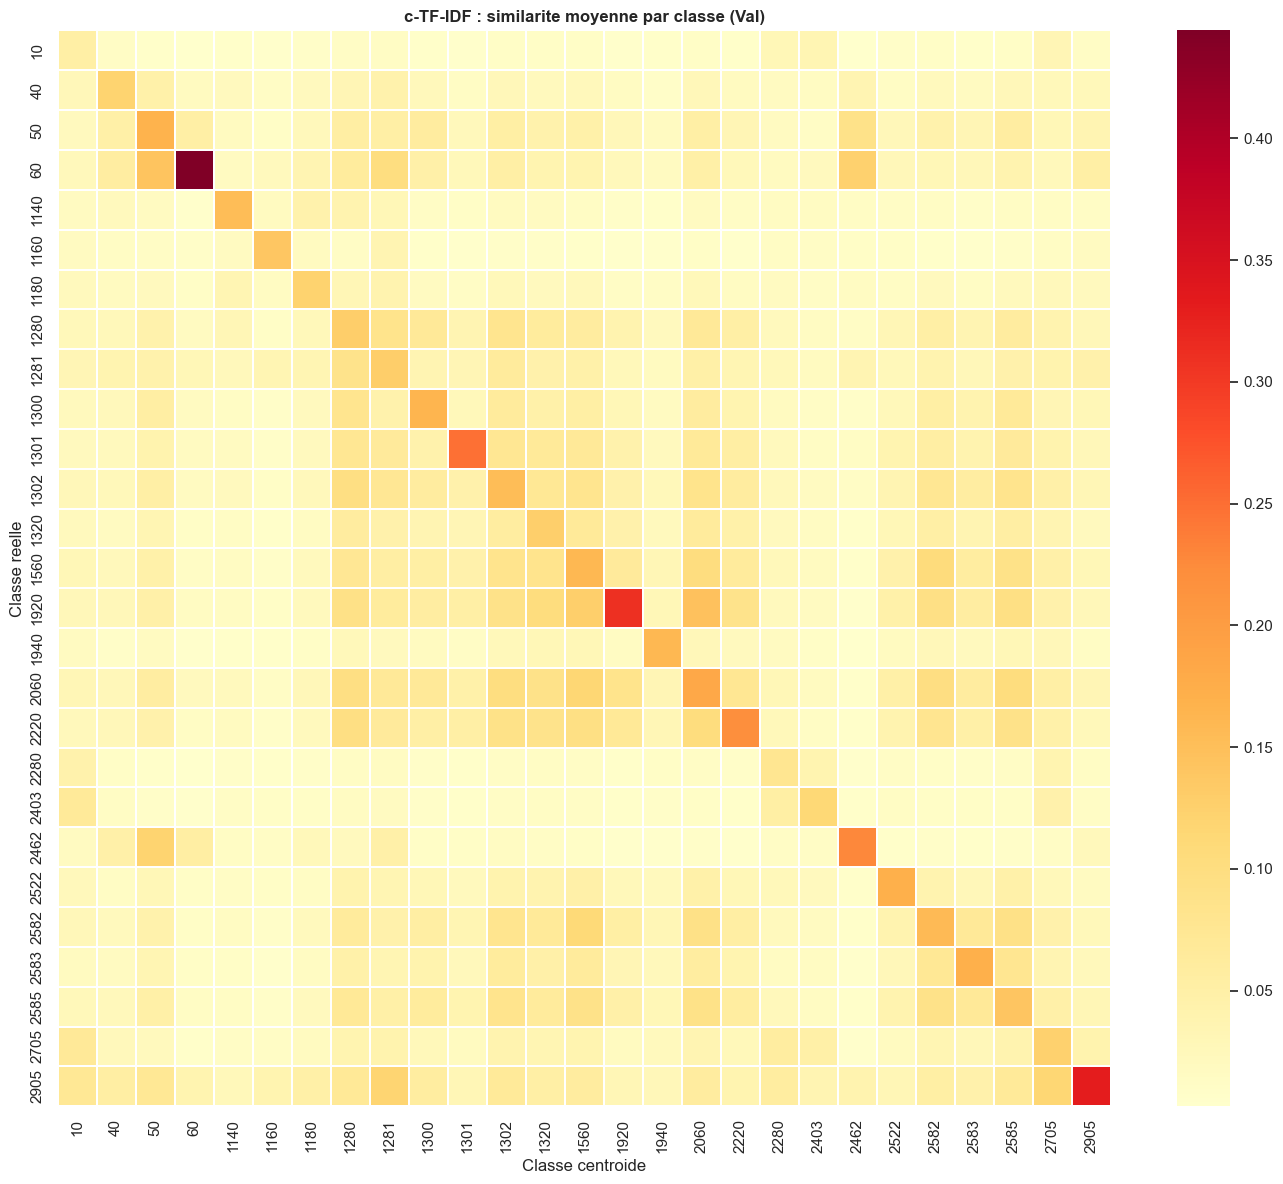

In [6]:
# Visualisation : heatmap de similarite moyenne c-TF-IDF par classe reelle
with open(CFG['models_dir'] / 'label_encoder.pkl', 'rb') as f:
    le = pickle.load(f)

sim_by_class = np.zeros((CFG['n_classes'], CFG['n_classes']))
for cls in range(CFG['n_classes']):
    mask = (y_val == cls)
    if mask.sum() > 0:
        sim_by_class[cls] = X_ctfidf_val[mask].mean(axis=0)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(sim_by_class, cmap='YlOrRd', ax=ax, linewidths=0.3,
            xticklabels=le.classes_, yticklabels=le.classes_,
            annot=False)
ax.set_title('c-TF-IDF : similarite moyenne par classe (Val)', fontweight='bold')
ax.set_xlabel('Classe centroide')
ax.set_ylabel('Classe reelle')
plt.tight_layout()
save_fig('ctfidf_similarity_heatmap.png')
plt.show()

---
## 4. Feature 2 : multilingual-e5-large (embeddings 1024-d)

Modèle `intfloat/multilingual-e5-large` — supporte nativement FR/EN/DE/ES.  
Préfixe `query: ` requis pour les phrases à encoder.  
Les embeddings sont mis en cache pour éviter les recalculs.

> ⚠️ ~15 min sur GPU / ~90 min sur CPU pour 60k phrases.

In [ ]:
E5_TRAIN_CACHE = CFG['processed'] / 'X_e5_train.npy'

if E5_TRAIN_CACHE.exists():
    X_e5_train = np.load(CFG['processed'] / 'X_e5_train.npy')
    X_e5_val   = np.load(CFG['processed'] / 'X_e5_val.npy')
    X_e5_test  = np.load(CFG['processed'] / 'X_e5_test.npy')
    print(f'E5 embeddings charges depuis cache : {X_e5_train.shape}')
else:
    print(f'Chargement modele : {CFG["e5_model_name"]}...')
    e5_model = SentenceTransformer(CFG['e5_model_name'], device=str(device))

    def encode_e5(texts: list, batch_size: int = 64) -> np.ndarray:
        prefixed = [CFG['e5_prefix'] + t for t in texts]
        embs = e5_model.encode(
            prefixed, batch_size=batch_size,
            show_progress_bar=True, normalize_embeddings=True,
            convert_to_numpy=True,
        )
        return embs.astype(np.float32)

    X_e5_train = encode_e5(train_df['combined_raw'].fillna('').tolist(), CFG['e5_batch_size'])
    X_e5_val   = encode_e5(val_df['combined_raw'].fillna('').tolist(),   CFG['e5_batch_size'])
    X_e5_test  = encode_e5(test_df['combined_raw'].fillna('').tolist(),  CFG['e5_batch_size'])

    np.save(CFG['processed'] / 'X_e5_train.npy', X_e5_train)
    np.save(CFG['processed'] / 'X_e5_val.npy',   X_e5_val)
    np.save(CFG['processed'] / 'X_e5_test.npy',  X_e5_test)
    print(f'E5 embeddings sauvegardes : {X_e5_train.shape}')

2026-05-17 16:56:03,297 INFO Load pretrained SentenceTransformer: intfloat/multilingual-e5-large


Chargement modele : intfloat/multilingual-e5-large...


Batches:  35%|███▌      | 329/929 [12:47<12:54,  1.29s/it]

---
## 5. Classifieurs sklearn-compatibles

### 5.1 MLP PyTorch (sklearn-compliant wrapper)

In [18]:
class MLP(nn.Module):
    def __init__(self, in_dim: int, hidden: tuple, out_dim: int, dropout: float = 0.3):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class MLPClassifier:
    """Wrapper sklearn-like autour du MLP PyTorch."""

    def __init__(self, in_dim: int, hidden: tuple = (256, 128, 64),
                 n_classes: int = 27, lr: float = 1e-3,
                 epochs: int = 50, patience: int = 10, batch: int = 256):
        self.in_dim = in_dim
        self.hidden = hidden
        self.n_classes = n_classes
        self.lr = lr
        self.epochs = epochs
        self.patience = patience
        self.batch = batch
        self.model = None

    def fit(self, X: np.ndarray, y: np.ndarray,
            X_val: np.ndarray = None, y_val: np.ndarray = None):
        self.model = MLP(self.in_dim, self.hidden, self.n_classes).to(device)
        opt = torch.optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=1e-4)
        criterion = nn.CrossEntropyLoss()

        Xt = torch.tensor(X, dtype=torch.float32)
        yt = torch.tensor(y, dtype=torch.long)
        loader = DataLoader(TensorDataset(Xt, yt), batch_size=self.batch, shuffle=True)

        best_f1, patience_ctr = 0.0, 0
        best_state = None

        for epoch in range(self.epochs):
            self.model.train()
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                loss = criterion(self.model(xb), yb)
                loss.backward()
                opt.step()

            if X_val is not None:
                preds = self.predict(X_val)
                f1 = f1_score(y_val, preds, average='weighted')
                if f1 > best_f1:
                    best_f1 = f1
                    best_state = {k: v.clone() for k, v in self.model.state_dict().items()}
                    patience_ctr = 0
                else:
                    patience_ctr += 1
                    if patience_ctr >= self.patience:
                        break

        if best_state is not None:
            self.model.load_state_dict(best_state)
        return self

    @torch.no_grad()
    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        self.model.eval()
        Xt = torch.tensor(X, dtype=torch.float32)
        loader = DataLoader(TensorDataset(Xt), batch_size=self.batch * 4)
        probas = []
        for (xb,) in loader:
            logits = self.model(xb.to(device))
            probas.append(torch.softmax(logits, dim=1).cpu().numpy())
        return np.vstack(probas)

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self.predict_proba(X).argmax(axis=1)

print('MLPClassifier defini.')

MLPClassifier defini.


---
## 6. Pipeline OOF (Out-Of-Fold)

La fonction `run_oof` entraîne un classifieur en K-Fold stratifié et retourne :
- Les probabilités OOF sur **Train** (sans leakage)
- Les probabilités moyennées sur **Val** et **Test**

In [13]:
def run_oof(
    X_train,
    y_train: np.ndarray,
    X_val,
    X_test,
    clf_factory,
    n_folds: int = 5,
    n_classes: int = 27,
    name: str = 'model',
) -> tuple:
    """
    Execute la procedure OOF sur K folds stratifies.

    Returns
    -------
    (P_oof_train, P_val, P_test) : np.ndarray de shape (n_samples, n_classes)
    """
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

    n_train = X_train.shape[0]
    n_val   = X_val.shape[0]
    n_test  = X_test.shape[0]

    P_oof_train  = np.zeros((n_train, n_classes), dtype=np.float32)
    P_val_folds  = np.zeros((n_val,   n_classes), dtype=np.float32)
    P_test_folds = np.zeros((n_test,  n_classes), dtype=np.float32)

    f1_folds = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
        print(f'  [{name}] Fold {fold+1}/{n_folds}...')
        X_tr = X_train[tr_idx]
        X_vl = X_train[val_idx]
        y_tr = y_train[tr_idx]
        y_vl = y_train[val_idx]

        clf = clf_factory()
        try:
            clf.fit(X_tr, y_tr, X_vl, y_vl)
        except TypeError:
            clf.fit(X_tr, y_tr)

        oof_probas = clf.predict_proba(X_vl)
        if sp.issparse(oof_probas):
            oof_probas = oof_probas.toarray()
        P_oof_train[val_idx] += oof_probas

        val_probas = clf.predict_proba(X_val)
        if sp.issparse(val_probas):
            val_probas = val_probas.toarray()
        P_val_folds += val_probas

        test_probas = clf.predict_proba(X_test)
        if sp.issparse(test_probas):
            test_probas = test_probas.toarray()
        P_test_folds += test_probas

        f1_fold = f1_score(y_vl, oof_probas.argmax(axis=1), average='weighted')
        f1_folds.append(f1_fold)
        print(f'       F1 OOF fold {fold+1} : {f1_fold:.4f}')

    P_val_folds  /= n_folds
    P_test_folds /= n_folds

    f1_oof = f1_score(y_train, P_oof_train.argmax(axis=1), average='weighted')
    print(f'\n  [{name}] F1 OOF global : {f1_oof:.4f}  (mean folds={np.mean(f1_folds):.4f} ± {np.std(f1_folds):.4f})')

    return P_oof_train, P_val_folds, P_test_folds

print('run_oof defini.')

run_oof defini.


---
## 7. Benchmark : 4 configurations texte

| ID  | Features                          | Classifieur |
|-----|-----------------------------------|-------------|
| T1  | TF-IDF seul                       | LogReg      |
| T2  | TF-IDF + c-TF-IDF                 | LogReg      |
| T3  | TF-IDF + c-TF-IDF + e5-large      | LogReg      |
| T4  | TF-IDF + c-TF-IDF + e5-large      | MLP         |

In [14]:
import scipy.sparse as sp

def make_text_features_sparse(tfidf, ctfidf, e5, use_ctfidf=True, use_e5=True):
    """TF-IDF (sparse) + c-TF-IDF + e5 assemblés en sparse — pour LogReg."""
    parts = [tfidf if sp.issparse(tfidf) else sp.csr_matrix(tfidf)]
    if use_ctfidf:
        parts.append(sp.csr_matrix(ctfidf.astype(np.float32)))
    if use_e5:
        parts.append(sp.csr_matrix(e5.astype(np.float32)))
    return sp.hstack(parts, format='csr')

def make_dense_features(ctfidf, e5, use_ctfidf=True, use_e5=True):
    """c-TF-IDF (27) + e5 (1024) en dense — pour le MLP (pas de TF-IDF : évite les 22 GiB)."""
    parts = []
    if use_ctfidf:
        parts.append(ctfidf.astype(np.float32))
    if use_e5:
        parts.append(e5.astype(np.float32))
    return np.hstack(parts)

configs = {
    'T1_tfidf_logreg': {
        'X_train': X_tfidf_train, 'X_val': X_tfidf_val, 'X_test': X_tfidf_test,
        'clf': 'logreg',
    },
    'T2_tfidf_ctfidf_logreg': {
        'X_train': sp.hstack([X_tfidf_train, sp.csr_matrix(X_ctfidf_train)]),
        'X_val':   sp.hstack([X_tfidf_val,   sp.csr_matrix(X_ctfidf_val)]),
        'X_test':  sp.hstack([X_tfidf_test,  sp.csr_matrix(X_ctfidf_test)]),
        'clf': 'logreg',
    },
    'T3_fusion_logreg': {
        'X_train': make_text_features_sparse(X_tfidf_train, X_ctfidf_train, X_e5_train),
        'X_val':   make_text_features_sparse(X_tfidf_val,   X_ctfidf_val,   X_e5_val),
        'X_test':  make_text_features_sparse(X_tfidf_test,  X_ctfidf_test,  X_e5_test),
        'clf': 'logreg',
    },
    'T4_fusion_mlp': {
        # MLP : e5 (1024) + c-TF-IDF (27) = 1051-d dense — TF-IDF exclu (trop large en dense)
        'X_train': make_dense_features(X_ctfidf_train, X_e5_train),
        'X_val':   make_dense_features(X_ctfidf_val,   X_e5_val),
        'X_test':  make_dense_features(X_ctfidf_test,  X_e5_test),
        'clf': 'mlp',
    },
}

print(f'T1 shape : {configs["T1_tfidf_logreg"]["X_train"].shape}')
print(f'T2 shape : {configs["T2_tfidf_ctfidf_logreg"]["X_train"].shape}')
print(f'T3 shape : {configs["T3_fusion_logreg"]["X_train"].shape}  (sparse)')
print(f'T4 shape : {configs["T4_fusion_mlp"]["X_train"].shape}  (dense)')

NameError: name 'X_ctfidf_train' is not defined

In [16]:
benchmark_results = []

for config_name, config in configs.items():
    cache_prefix = CFG['processed'] / f'P_{config_name}'
    oof_cache = Path(str(cache_prefix) + '_oof_train.npy')

    if oof_cache.exists():
        P_oof  = np.load(str(cache_prefix) + '_oof_train.npy')
        P_val  = np.load(str(cache_prefix) + '_val.npy')
        P_test = np.load(str(cache_prefix) + '_test.npy')
        f1_oof  = f1_score(y_train, P_oof.argmax(axis=1), average='weighted')
        f1_val  = f1_score(y_val,   P_val.argmax(axis=1), average='weighted')
        f1_test = f1_score(y_test,  P_test.argmax(axis=1), average='weighted')
        print(f'[CACHE] {config_name} : OOF={f1_oof:.4f}  Val={f1_val:.4f}  Test={f1_test:.4f}')
    else:
        in_dim = config['X_train'].shape[1]

        if config['clf'] == 'logreg':
            clf_factory = lambda: LogisticRegression(
                C=CFG['logreg_C'], solver=CFG['logreg_solver'],
                max_iter=CFG['logreg_max_iter'], class_weight='balanced',
                n_jobs=-1, multi_class='multinomial'
            )
        else:  # mlp
            clf_factory = lambda in_d=in_dim: MLPClassifier(
                in_dim=in_d, hidden=CFG['mlp_hidden'],
                n_classes=CFG['n_classes'], lr=CFG['mlp_lr'],
                epochs=CFG['mlp_epochs'], patience=CFG['mlp_patience'],
                batch=CFG['mlp_batch']
            )

        # Sparse OK pour LogReg ; dense pour MLP (déjà dense depuis make_dense_features)
        X_tr = config['X_train']
        X_vl = config['X_val']
        X_te = config['X_test']

        print(f'\n=== {config_name} ===')
        P_oof, P_val, P_test = run_oof(
            X_tr, y_train, X_vl, X_te,
            clf_factory=clf_factory,
            n_folds=CFG['n_folds'],
            n_classes=CFG['n_classes'],
            name=config_name,
        )

        np.save(str(cache_prefix) + '_oof_train.npy', P_oof)
        np.save(str(cache_prefix) + '_val.npy',   P_val)
        np.save(str(cache_prefix) + '_test.npy',  P_test)

        f1_oof  = f1_score(y_train, P_oof.argmax(axis=1), average='weighted')
        f1_val  = f1_score(y_val,   P_val.argmax(axis=1), average='weighted')
        f1_test = f1_score(y_test,  P_test.argmax(axis=1), average='weighted')

    benchmark_results.append({
        'Config': config_name,
        'F1_OOF': round(f1_oof, 4),
        'F1_Val': round(f1_val, 4),
        'F1_Test': round(f1_test, 4),
        'Classifieur': config['clf'],
    })

bench_df = pd.DataFrame(benchmark_results).sort_values('F1_Test', ascending=False)
print('\n=== BENCHMARK TEXTE ===')
print(bench_df.to_string(index=False))


=== T1_tfidf_logreg ===
  [T1_tfidf_logreg] Fold 1/5...
       F1 OOF fold 1 : 0.7811
  [T1_tfidf_logreg] Fold 2/5...
       F1 OOF fold 2 : 0.7801
  [T1_tfidf_logreg] Fold 3/5...
       F1 OOF fold 3 : 0.7808
  [T1_tfidf_logreg] Fold 4/5...
       F1 OOF fold 4 : 0.7734
  [T1_tfidf_logreg] Fold 5/5...
       F1 OOF fold 5 : 0.7808

  [T1_tfidf_logreg] F1 OOF global : 0.7792  (mean folds=0.7792 ± 0.0029)

=== T2_tfidf_ctfidf_logreg ===
  [T2_tfidf_ctfidf_logreg] Fold 1/5...
       F1 OOF fold 1 : 0.7861
  [T2_tfidf_ctfidf_logreg] Fold 2/5...
       F1 OOF fold 2 : 0.7833
  [T2_tfidf_ctfidf_logreg] Fold 3/5...
       F1 OOF fold 3 : 0.7850
  [T2_tfidf_ctfidf_logreg] Fold 4/5...
       F1 OOF fold 4 : 0.7787
  [T2_tfidf_ctfidf_logreg] Fold 5/5...
       F1 OOF fold 5 : 0.7836

  [T2_tfidf_ctfidf_logreg] F1 OOF global : 0.7833  (mean folds=0.7833 ± 0.0025)

=== T3_fusion_logreg ===
  [T3_fusion_logreg] Fold 1/5...
       F1 OOF fold 1 : 0.8322
  [T3_fusion_logreg] Fold 2/5...
       F1 O

### 7.1 Graphique benchmark

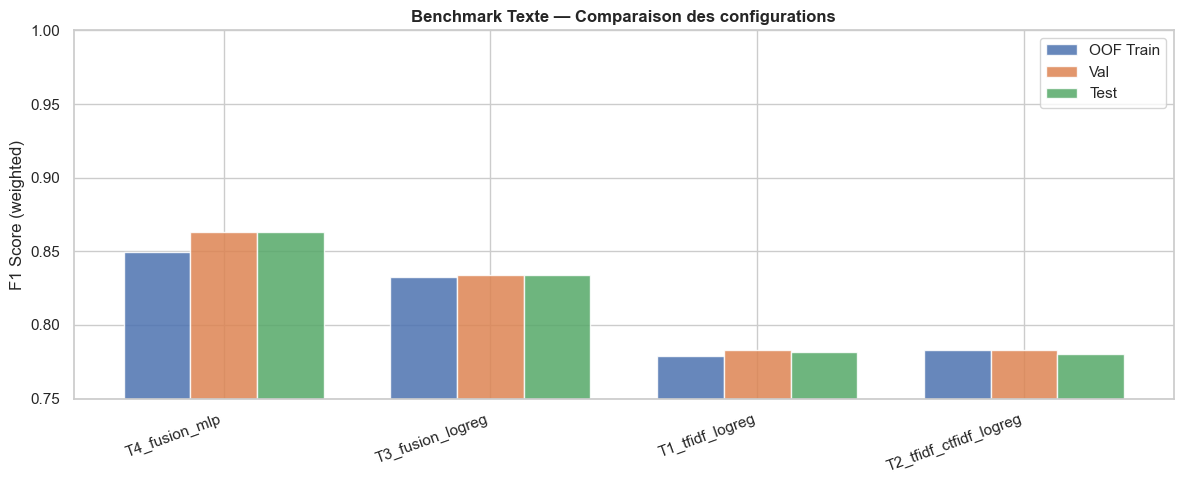

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(bench_df))
w = 0.25
for i, (col, label) in enumerate([('F1_OOF', 'OOF Train'), ('F1_Val', 'Val'), ('F1_Test', 'Test')]):
    ax.bar(x + i * w, bench_df[col], width=w, label=label, alpha=0.85)
ax.set_xticks(x + w)
ax.set_xticklabels(bench_df['Config'], rotation=20, ha='right')
ax.set_ylim(0.75, 1.0)
ax.set_ylabel('F1 Score (weighted)')
ax.set_title('Benchmark Texte — Comparaison des configurations', fontweight='bold')
ax.legend()
plt.tight_layout()
save_fig('texte_benchmark.png')
plt.show()

---
## 8. Sélection du meilleur modèle & export OOF pour Stacking

In [18]:
best_config = bench_df.iloc[0]['Config']
print(f'Meilleure configuration : {best_config}')
print(f'F1 Test : {bench_df.iloc[0]["F1_Test"]:.4f}')

cache_prefix = CFG['processed'] / f'P_{best_config}'
P_text_oof_train = np.load(str(cache_prefix) + '_oof_train.npy')
P_text_val       = np.load(str(cache_prefix) + '_val.npy')
P_text_test      = np.load(str(cache_prefix) + '_test.npy')

# Alias standard pour le notebook 5 (stacking)
np.save(CFG['processed'] / 'P_text_oof_train.npy', P_text_oof_train)
np.save(CFG['processed'] / 'P_text_val.npy',       P_text_val)
np.save(CFG['processed'] / 'P_text_test.npy',      P_text_test)

print('OOF texte sauvegardees sous P_text_*.npy')

Meilleure configuration : T4_fusion_mlp
F1 Test : 0.8632
OOF texte sauvegardees sous P_text_*.npy


Meilleure configuration : T4_fusion_mlp
F1 Test : 0.8632

---
## 9. CamemBERT — extracteur gelé vs fine-tuning

Deux approches comparées sur `text_fr` :

| ID  | Approche                        | Durée    |
|-----|---------------------------------|----------|
| 9.1 | **Fine-tuning end-to-end**      | ~5h GPU  |
| 9.2 | **Extracteur gelé + MLP**       | ~20 min  |

> Les deux utilisent `run_oof` (5 folds) → 3 fichiers `.npy` chacun.

In [16]:
CAM_VAL_CACHE  = CFG['processed'] / 'P_camembert_val.npy'
CAM_TEST_CACHE = CFG['processed'] / 'P_camembert_test.npy'
CAM_OOF_CACHE  = CFG['processed'] / 'P_camembert_oof_train.npy'

try:
    from transformers import CamembertTokenizer, CamembertForSequenceClassification
    from transformers import get_linear_schedule_with_warmup
    from torch.utils.data import Dataset
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'transformers', 'sentencepiece'])
    from transformers import CamembertTokenizer, CamembertForSequenceClassification
    from transformers import get_linear_schedule_with_warmup
    from torch.utils.data import Dataset

CAM_CFG = {
    'model_name':   'camembert-base',
    'max_length':   128,
    'batch_size':   32,
    'epochs':       5,
    'lr':           2e-5,
    'warmup_ratio': 0.1,
    'n_classes':    CFG['n_classes'],
}

tokenizer_cam = CamembertTokenizer.from_pretrained(CAM_CFG['model_name'])


class CamDataset(Dataset):
    def __init__(self, texts, labels=None):
        self.encodings = tokenizer_cam(
            list(texts), truncation=True, padding='max_length',
            max_length=CAM_CFG['max_length'], return_tensors='pt',
        )
        self.labels = labels

    def __len__(self):
        return self.encodings['input_ids'].shape[0]

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        if self.labels is not None:
            item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


def train_camembert(texts_tr, y_tr, texts_vl, y_vl):
    model = CamembertForSequenceClassification.from_pretrained(
        CAM_CFG['model_name'], num_labels=CAM_CFG['n_classes']
    ).to(device)

    train_dl = DataLoader(CamDataset(texts_tr, y_tr), batch_size=CAM_CFG['batch_size'], shuffle=True)
    val_dl   = DataLoader(CamDataset(texts_vl, y_vl), batch_size=CAM_CFG['batch_size'] * 2)

    optimizer    = torch.optim.AdamW(model.parameters(), lr=CAM_CFG['lr'], weight_decay=0.01)
    total_steps  = len(train_dl) * CAM_CFG['epochs']
    warmup_steps = int(total_steps * CAM_CFG['warmup_ratio'])
    scheduler    = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

    best_f1, best_state = 0.0, None
    for epoch in range(CAM_CFG['epochs']):
        model.train()
        for batch in tqdm(train_dl, desc=f'Epoch {epoch+1}/{CAM_CFG["epochs"]}', leave=False):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            outputs.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

        model.eval()
        preds = []
        with torch.no_grad():
            for batch in val_dl:
                batch = {k: v.to(device) for k, v in batch.items()}
                preds.extend(model(**batch).logits.argmax(-1).cpu().numpy())
        f1_ep = f1_score(y_vl, preds, average='weighted')
        print(f'  Epoch {epoch+1}: Val F1={f1_ep:.4f}')
        if f1_ep > best_f1:
            best_f1 = f1_ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model


@torch.no_grad()
def get_cam_probs(model, texts, batch_size=64):
    model.eval()
    loader = DataLoader(CamDataset(texts), batch_size=batch_size)
    probs  = []
    for batch in loader:
        batch  = {k: v.to(device) for k, v in batch.items()}
        logits = model(**batch).logits
        probs.append(torch.softmax(logits, dim=-1).cpu().numpy())
    return np.vstack(probs).astype(np.float32)


def get_text_fr(df_fr, df_orig):
    """text_fr avec fallback sur combined_raw si traduction manquante/échouée."""
    return df_fr['text_fr'].fillna(df_orig['combined_raw']).fillna('').tolist()


class CamembertClassifier:
    """Wrapper sklearn-compatible pour run_oof — entrée : np.array de strings."""
    def fit(self, texts, y, texts_val=None, y_val=None):
        self.model_ = train_camembert(texts.tolist(), y, texts_val.tolist(), y_val)
        return self

    def predict_proba(self, texts):
        return get_cam_probs(self.model_, texts.tolist())


# ── OOF via run_oof (identique à T1-T4) ──────────────────────────────────────
if CAM_VAL_CACHE.exists() and CAM_TEST_CACHE.exists() and CAM_OOF_CACHE.exists():
    P_cam_oof  = np.load(CAM_OOF_CACHE)
    P_cam_val  = np.load(CAM_VAL_CACHE)
    P_cam_test = np.load(CAM_TEST_CACHE)
    print('[CACHE] CamemBERT chargé depuis cache.')
else:
    texts_train_arr = np.array(get_text_fr(train_fr, train_df))
    texts_val_arr   = np.array(get_text_fr(val_fr,   val_df))
    texts_test_arr  = np.array(get_text_fr(test_fr,  test_df))

    P_cam_oof, P_cam_val, P_cam_test = run_oof(
        texts_train_arr, y_train, texts_val_arr, texts_test_arr,
        clf_factory=CamembertClassifier,
        n_folds=CFG['n_folds'],
        n_classes=CFG['n_classes'],
        name='CamemBERT',
    )

    np.save(CAM_OOF_CACHE,  P_cam_oof)
    np.save(CAM_VAL_CACHE,  P_cam_val)
    np.save(CAM_TEST_CACHE, P_cam_test)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f'\n=== RÉSUMÉ CAMEMBERT ===')
print(f'  OOF  F1 : {f1_score(y_train, P_cam_oof.argmax(1), average="weighted"):.4f}')
print(f'  Val  F1 : {f1_score(y_val,   P_cam_val.argmax(1), average="weighted"):.4f}')
print(f'  Test F1 : {f1_score(y_test,  P_cam_test.argmax(1), average="weighted"):.4f}')
print(f'\nFichiers prêts pour NB5 :')
for p in [CAM_OOF_CACHE, CAM_VAL_CACHE, CAM_TEST_CACHE]:
    print(f'  [{"OK" if p.exists() else "MANQUANT"}] {p.name}')


  [CamemBERT] Fold 1/5...


Some weights of CamembertForSequenceClassification were not initialized from the model checkpoint at camembert-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Epoch 1: Val F1=0.7582


  Epoch 2: Val F1=0.8338


  Epoch 3: Val F1=0.8467


...

  Epoch 1: Val F1=0.7684


  Epoch 2: Val F1=0.8389


  Epoch 3: Val F1=0.8515


  Epoch 4: Val F1=0.8630


  Epoch 5: Val F1=0.8687
       F1 OOF fold 5 : 0.8687

  [CamemBERT] F1 OOF global : 0.8672  (mean folds=0.8672 ± 0.0030)

=== RÉSUMÉ CAMEMBERT ===
  OOF  F1 : 0.8672
  Val  F1 : 0.8769
  Test F1 : 0.8717

Fichiers prêts pour NB5 :
  [OK] P_camembert_oof_train.npy
  [OK] P_camembert_val.npy
  [OK] P_camembert_test.npy


### 9.2 Extracteur gelé + MLP

CamemBERT utilisé comme extracteur de features **gelé** (weights figés, pas de backprop).
Token `[CLS]` → embedding 768-d mis en cache → MLP entraîné par-dessus.
Comparable à E5 mais avec un modèle français spécialisé.

In [19]:
CAM_FROZEN_TRAIN_PATH = CFG['processed'] / 'X_cam_frozen_train.npy'
CAM_FROZEN_VAL_PATH   = CFG['processed'] / 'X_cam_frozen_val.npy'
CAM_FROZEN_TEST_PATH  = CFG['processed'] / 'X_cam_frozen_test.npy'

CAM_FROZEN_OOF_CACHE  = CFG['processed'] / 'P_cam_frozen_oof_train.npy'
CAM_FROZEN_VAL_CACHE  = CFG['processed'] / 'P_cam_frozen_val.npy'
CAM_FROZEN_TEST_CACHE = CFG['processed'] / 'P_cam_frozen_test.npy'

# ── Extraction des embeddings gelés (CLS token, 768-d) ───────────────────────
if CAM_FROZEN_TRAIN_PATH.exists():
    X_cam_frozen_train = np.load(CAM_FROZEN_TRAIN_PATH)
    X_cam_frozen_val   = np.load(CAM_FROZEN_VAL_PATH)
    X_cam_frozen_test  = np.load(CAM_FROZEN_TEST_PATH)
    print(f'[CACHE] Embeddings CamemBERT gelé : {X_cam_frozen_train.shape}')
else:
    from transformers import CamembertModel
    cam_frozen = CamembertModel.from_pretrained(CAM_CFG['model_name']).to(device)
    cam_frozen.eval()

    @torch.no_grad()
    def encode_cam_frozen(texts, batch_size=64):
        ds     = CamDataset(texts)  # réutilise tokenizer_cam défini en 9.1
        loader = DataLoader(ds, batch_size=batch_size)
        embs   = []
        for batch in tqdm(loader, desc='CamemBERT frozen'):
            batch = {k: v.to(device) for k, v in batch.items()}
            out   = cam_frozen(**batch)
            embs.append(out.last_hidden_state[:, 0].cpu().numpy())  # CLS
        return np.vstack(embs).astype(np.float32)

    texts_train = get_text_fr(train_fr, train_df)
    texts_val   = get_text_fr(val_fr,   val_df)
    texts_test  = get_text_fr(test_fr,  test_df)

    print('Extraction embeddings gelés...')
    X_cam_frozen_train = encode_cam_frozen(texts_train)
    X_cam_frozen_val   = encode_cam_frozen(texts_val)
    X_cam_frozen_test  = encode_cam_frozen(texts_test)

    np.save(CAM_FROZEN_TRAIN_PATH, X_cam_frozen_train)
    np.save(CAM_FROZEN_VAL_PATH,   X_cam_frozen_val)
    np.save(CAM_FROZEN_TEST_PATH,  X_cam_frozen_test)

    del cam_frozen
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f'Embeddings gelés sauvegardés : {X_cam_frozen_train.shape}')  # (N, 768)

# ── OOF MLP sur embeddings gelés ─────────────────────────────────────────────
if CAM_FROZEN_OOF_CACHE.exists():
    P_cam_frozen_oof  = np.load(CAM_FROZEN_OOF_CACHE)
    P_cam_frozen_val  = np.load(CAM_FROZEN_VAL_CACHE)
    P_cam_frozen_test = np.load(CAM_FROZEN_TEST_CACHE)
    print('[CACHE] OOF CamemBERT gelé+MLP chargé.')
else:
    in_dim = X_cam_frozen_train.shape[1]  # 768
    P_cam_frozen_oof, P_cam_frozen_val, P_cam_frozen_test = run_oof(
        X_cam_frozen_train, y_train, X_cam_frozen_val, X_cam_frozen_test,
        clf_factory=lambda: MLPClassifier(
            in_dim=in_dim, hidden=CFG['mlp_hidden'],
            n_classes=CFG['n_classes'], lr=CFG['mlp_lr'],
            epochs=CFG['mlp_epochs'], patience=CFG['mlp_patience'],
            batch=CFG['mlp_batch'],
        ),
        n_folds=CFG['n_folds'],
        n_classes=CFG['n_classes'],
        name='CamemBERT-frozen+MLP',
    )
    np.save(CAM_FROZEN_OOF_CACHE,  P_cam_frozen_oof)
    np.save(CAM_FROZEN_VAL_CACHE,  P_cam_frozen_val)
    np.save(CAM_FROZEN_TEST_CACHE, P_cam_frozen_test)

f1_oof  = f1_score(y_train, P_cam_frozen_oof.argmax(1), average='weighted')
f1_val  = f1_score(y_val,   P_cam_frozen_val.argmax(1), average='weighted')
f1_test = f1_score(y_test,  P_cam_frozen_test.argmax(1), average='weighted')

print(f'\n=== RÉSUMÉ CAMEMBERT GELÉ + MLP ===')
print(f'  OOF  F1 : {f1_oof:.4f}')
print(f'  Val  F1 : {f1_val:.4f}')
print(f'  Test F1 : {f1_test:.4f}')

# ── Comparaison des deux approches ───────────────────────────────────────────
print(f'\n=== COMPARAISON CAMEMBERT ===')
rows = [
    ('Gelé + MLP',       f1_score(y_train, P_cam_frozen_oof.argmax(1),  average="weighted"),
                         f1_score(y_val,   P_cam_frozen_val.argmax(1),  average="weighted"),
                         f1_score(y_test,  P_cam_frozen_test.argmax(1), average="weighted")),
]
if CAM_OOF_CACHE.exists():
    P_ft_oof  = np.load(CAM_OOF_CACHE)
    P_ft_val  = np.load(CAM_VAL_CACHE)
    P_ft_test = np.load(CAM_TEST_CACHE)
    rows.insert(0, ('Fine-tuning E2E',
                    f1_score(y_train, P_ft_oof.argmax(1),  average="weighted"),
                    f1_score(y_val,   P_ft_val.argmax(1),  average="weighted"),
                    f1_score(y_test,  P_ft_test.argmax(1), average="weighted")))

print(f'  {"Approche":<20} {"OOF":>8} {"Val":>8} {"Test":>8}')
print(f'  {"-"*46}')
for name, oof, val, tst in rows:
    print(f'  {name:<20} {oof:>8.4f} {val:>8.4f} {tst:>8.4f}')


[CACHE] Embeddings CamemBERT gelé : (59441, 768)
  [CamemBERT-frozen+MLP] Fold 1/5...
       F1 OOF fold 1 : 0.8141
  [CamemBERT-frozen+MLP] Fold 2/5...
       F1 OOF fold 2 : 0.8202
  [CamemBERT-frozen+MLP] Fold 3/5...
       F1 OOF fold 3 : 0.8224
  [CamemBERT-frozen+MLP] Fold 4/5...
       F1 OOF fold 4 : 0.8177
  [CamemBERT-frozen+MLP] Fold 5/5...
       F1 OOF fold 5 : 0.8199

  [CamemBERT-frozen+MLP] F1 OOF global : 0.8188  (mean folds=0.8188 ± 0.0028)

=== RÉSUMÉ CAMEMBERT GELÉ + MLP ===
  OOF  F1 : 0.8188
  Val  F1 : 0.8353
  Test F1 : 0.8327

=== COMPARAISON CAMEMBERT ===
  Approche                  OOF      Val     Test
  ----------------------------------------------
  Fine-tuning E2E        0.8672   0.8769   0.8717
  Gelé + MLP             0.8188   0.8353   0.8327


---
## 10. Interprétabilité Texte

### 10.1 Surrogate LogReg pour l'importance des mots

> **Pourquoi LogReg sur TF-IDF seul, et pas le meilleur modèle (T4 MLP) ?**
>
> 1. Le MLP n'expose pas de coefficients par token — ses poids internes encodent
>    des interactions non-linéaires entre 1051 dimensions, pas une importance directe.
> 2. Les embeddings e5 (1024-d) ne correspondent à aucun token lisible :
>    leurs dimensions n'ont pas de sémantique humaine.
>
> On entraîne donc un **surrogate LogReg sur TF-IDF seul** (50k features sparse) :
> `coef_[classe, token]` = contribution directe du mot → interprétable, rapide.
> C'est une approximation du MLP, mais fidèle pour les tokens les plus discriminants.
>
> Ce surrogate est aussi utilisé dans `streamlit_app/pipeline.py`
> (`highlight_important_words`) pour colorier les mots dans l'interface.

Entraînement surrogate LogReg (TF-IDF seul, max_iter=300)...
Surrogate sauvegardé : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\models\clean\logreg_surrogate.pkl


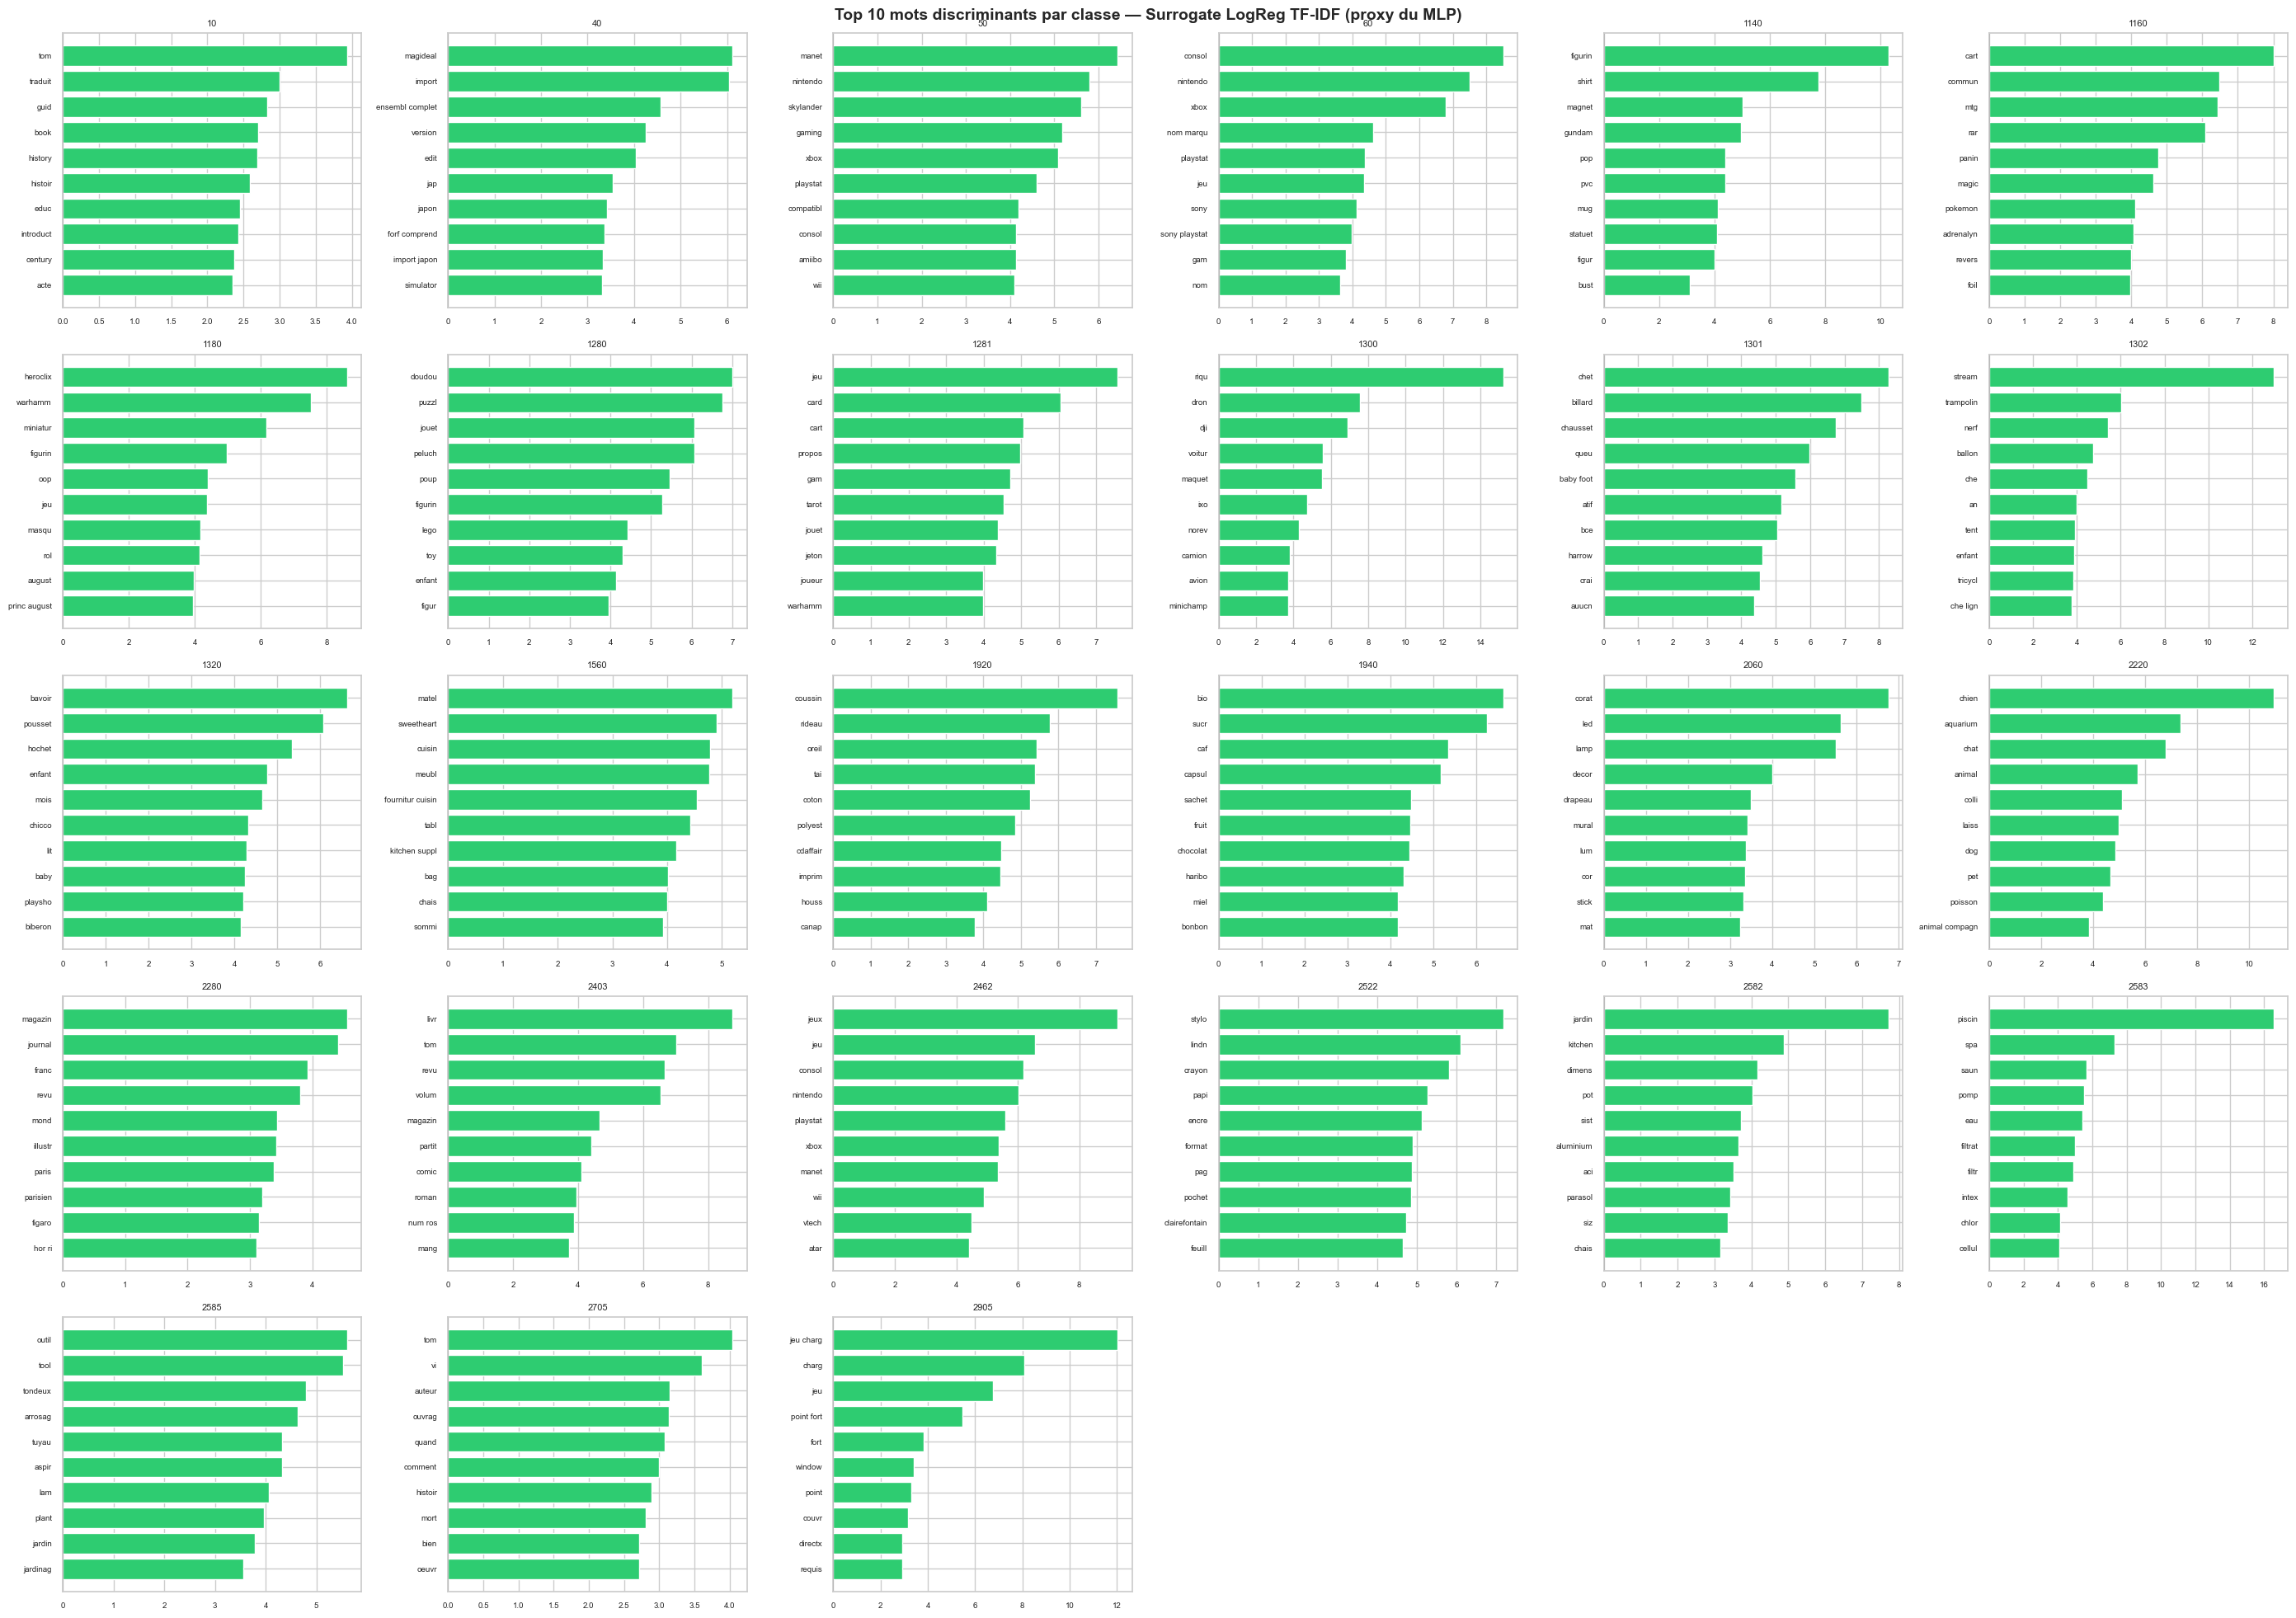

In [20]:
SURROGATE_PATH = CFG['models_dir'] / 'logreg_surrogate.pkl'

if SURROGATE_PATH.exists():
    with open(SURROGATE_PATH, 'rb') as f:
        clf_interp = pickle.load(f)
    print('Surrogate chargé depuis cache.')
else:
    # TF-IDF seul (50k sparse) : pas d'e5 → inutile pour lire les tokens, et beaucoup plus rapide
    print('Entraînement surrogate LogReg (TF-IDF seul, max_iter=300)...')
    clf_interp = LogisticRegression(
        C=1.0, solver='saga', max_iter=300,
        class_weight='balanced', n_jobs=-1, multi_class='multinomial'
    )
    clf_interp.fit(X_tfidf_train, y_train)
    with open(SURROGATE_PATH, 'wb') as f:
        pickle.dump(clf_interp, f)
    print(f'Surrogate sauvegardé : {SURROGATE_PATH}')

feature_names = tfidf.get_feature_names_out()
tfidf_coef = clf_interp.coef_  # (n_classes, 50000)

with open(CFG['models_dir'] / 'label_encoder.pkl', 'rb') as f:
    le = pickle.load(f)

n_top = 10
fig, axes = plt.subplots(5, 6, figsize=(28, 20))
axes = axes.flatten()

for cls_idx in range(CFG['n_classes']):
    ax = axes[cls_idx]
    coefs = tfidf_coef[cls_idx]
    top_idx = np.argsort(coefs)[-n_top:][::-1]
    top_words = feature_names[top_idx]
    top_scores = coefs[top_idx]
    colors = ['#2ecc71' if s > 0 else '#e74c3c' for s in top_scores]
    ax.barh(top_words[::-1], top_scores[::-1], color=colors[::-1])
    ax.set_title(f'{le.classes_[cls_idx]}', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.axvline(0, color='black', linewidth=0.5)

for ax in axes[CFG['n_classes']:]:
    ax.axis('off')

plt.suptitle('Top 10 mots discriminants par classe — Surrogate LogReg TF-IDF (proxy du MLP)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
save_fig('texte_logreg_coefficients.png')
plt.show()

### 10.2 Analyse des erreurs par classe

In [21]:
y_pred_val = P_text_val.argmax(axis=1)
f1_per_class_val = f1_score(y_val, y_pred_val, average=None)

# Classes les plus difficiles
hard_idx = np.argsort(f1_per_class_val)[:5]
print('Classes les plus difficiles (texte) :')
for idx in hard_idx:
    code = le.classes_[idx]
    print(f'  prdtypecode={code} : F1={f1_per_class_val[idx]:.3f}')

    # Exemples d'erreurs
    mask_true = (y_val == idx)
    mask_pred = (y_pred_val == idx)
    fp_idx = np.where(~mask_true & mask_pred)[0][:3]
    fn_idx = np.where(mask_true & ~mask_pred)[0][:3]

    if len(fn_idx) > 0:
        print(f'  Faux negatifs (manques) :')
        for i in fn_idx:
            print(f'    Predit={le.classes_[y_pred_val[i]]} | Texte: {str(val_df["combined_raw"].iloc[i])[:80]}...')
    print()

Classes les plus difficiles (texte) :
  prdtypecode=10 : F1=0.646
  Faux negatifs (manques) :
    Predit=2705 | Texte: La Corruption Du Meilleur Engendre Le Pire...
    Predit=2280 | Texte: Le Saint Detective Magazine N°33- Novembre 1957- Le Planteur De Bananes Blochman...
    Predit=2522 | Texte: Giant Grab A Pencil Bk Of...

  prdtypecode=1281 : F1=0.653
  Faux negatifs (manques) :
    Predit=1280 | Texte: Rc Pelle Voiture Construction Camion Chenilles Digger Jouets Électriques De Cont...
    Predit=1280 | Texte: Magie Inductive Truck [Follows Black Line] Magic Toy Car Pour Les Enfants Et Les...
    Predit=1280 | Texte: Vacarme Dans La Jungle Pièces En Bois...

  prdtypecode=1180 : F1=0.686
  Faux negatifs (manques) :
    Predit=1280 | Texte: Fortune Teller Miracle Fish Magic Trick (Pack Of 10) Fortune Teller FishFUN FOR ...
    Predit=1320 | Texte: Tomy Le Voyage D'arlo - Arlo & Spot Ultime...
    Predit=50 | Texte: Lego Dimensions - Toy Tag Gimli - Seigneur Des Anneaux Lotr Pour Ps

---
## 11. Récapitulatif

In [ ]:
print('=' * 65)
print('  NOTEBOOK 3 — BILAN EXPERIENCES TEXTE')
print('=' * 65)
print()
print(bench_df.to_string(index=False))
print()
print(f'Meilleure config : {best_config}')
print(f'F1 Test          : {bench_df.iloc[0]["F1_Test"]:.4f}')
print()
print('FICHIERS OOF GENERES (pour notebook 5) :')
for p in [
    CFG['processed'] / 'P_text_oof_train.npy',
    CFG['processed'] / 'P_text_val.npy',
    CFG['processed'] / 'P_text_test.npy',
]:
    print(f'  [{"OK" if p.exists() else "MANQUANT"}] {p.name}  shape={np.load(str(p)).shape if p.exists() else "N/A"}')
print()
print('PROCHAIN NOTEBOOK : 04_experiments_images.ipynb')

  NOTEBOOK 3 — BILAN EXPERIENCES TEXTE

                Config  F1_OOF  F1_Val  F1_Test Classifieur
         T4_fusion_mlp  0.8497  0.8632   0.8632         mlp
      T3_fusion_logreg  0.8329  0.8341   0.8341      logreg
       T1_tfidf_logreg  0.7792  0.7829   0.7814      logreg
T2_tfidf_ctfidf_logreg  0.7833  0.7828   0.7801      logreg

Meilleure config : T4_fusion_mlp
F1 Test          : 0.8632

FICHIERS OOF GENERES (pour notebook 5) :
  [OK] P_text_oof_train.npy  shape=(59441, 27)
  [OK] P_text_val.npy  shape=(12737, 27)
  [OK] P_text_test.npy  shape=(12738, 27)

PROCHAIN NOTEBOOK : 04_experiments_images.ipynb


: 